# Projeto Final

## Leitura Dados

In [61]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
from IPython.display import display

In [62]:
# Caminho para o diretório
base_path = 'C:/Users/eduar/Cliente_BLE'

DADOS = []
ROTU = []

def criar_janelas(dados, rotulo, tamanho_janela, defasagem):
    janelas = []
    rotulos = []
    
    # Cria janels
    for i in range(0, len(dados) - tamanho_janela + 1, defasagem):
        janela = dados[i:i + tamanho_janela]
        janelas.append(janela)
        rotulos.append(rotulo)  # Repete o rótulo 
    
    return janelas, rotulos

# Função para processar CSV
def processar_csv(arquivo, tamanho_janela, defasagem):
    
    df = pd.read_csv(arquivo, header=None)  
    rotulo = df.iloc[0, 0]
    dados = df.iloc[1:, 0].astype(float).values  
    
    return criar_janelas(dados, rotulo, tamanho_janela, defasagem)



In [63]:
# Parâmetros das janelas
tamanho_janela = 150
defasagem = 50

# Busca arquivos no diretório
for arquivo in os.listdir(base_path):
    if arquivo.endswith('.csv'):
        caminho_arquivo = os.path.join(base_path, arquivo)
        
        janelas, rotulos = processar_csv(caminho_arquivo, tamanho_janela, defasagem)
        
        DADOS.extend(janelas)
        ROTU.extend(rotulos)

# lista para arrays
DADOS = np.array(DADOS)  
ROTU = np.array(ROTU)  

# Converte para int 
rotu_mapping = {'TP': 0, 'TD': 1, 'TE': 2, 'TF': 3}
ROTU = np.array([rotu_mapping[label] for label in ROTU], dtype=np.int32)

print(f"Forma dos dados: {DADOS.shape}")
print(f"Forma dos rótulos: {ROTU.shape}")

Forma dos dados: (124, 150)
Forma dos rótulos: (124,)


Janela 0 (Rótulo: 1):


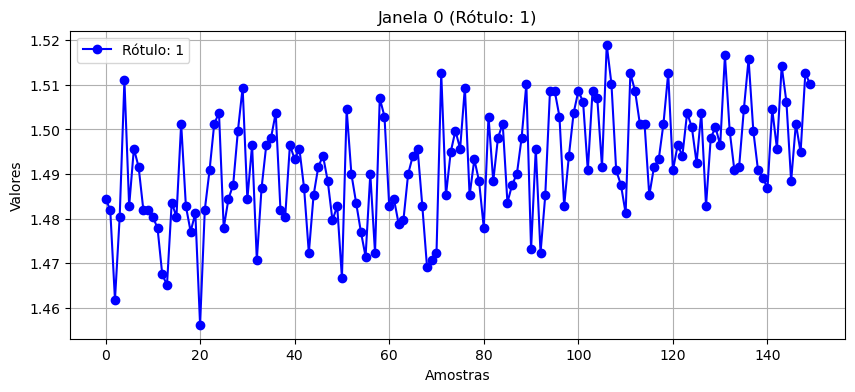

In [64]:

# Escolhe janela p/ visualizar
visu_dado = 0  

janela = DADOS[visu_dado]
rotulo = ROTU[visu_dado]

# Visualizar os valores da janela
print(f"Janela {visu_dado} (Rótulo: {rotulo}):")

# Plotar a janela
plt.figure(figsize=(10, 4))
plt.plot(janela, marker='o', linestyle='-', color='b', label=f'Rótulo: {rotulo}')
plt.title(f"Janela {visu_dado} (Rótulo: {rotulo})")
plt.xlabel("Amostras")
plt.ylabel("Valores")
plt.legend()
plt.grid()
plt.show()

## Data Augmentation

In [78]:
# Parâmetro de ruído 
noise_factor = 0.01

# Parâmetro de escala
scale_factor = 0.1  

# Deslocar o sinal no tempo
def shift_signal(data, max_shift):
    shift = np.random.randint(-max_shift, max_shift)
    return np.roll(data, shift, axis=0)

shift_max = 20  # Máximo deslocamento

from scipy.ndimage import gaussian_filter1d

# # jitter, escalonamento, deslocamento e suavização
# DADOS_noise = DADOS + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=DADOS.shape)
# DADOS_aug = DADOS_noise * (1 + scale_factor * np.random.uniform(-1, 1, size=DADOS.shape))
# DADOS_aug = gaussian_filter1d(DADOS, sigma=2, axis=1) 
# DADOS_aug = np.array([shift_signal(dado, shift_max) for dado in DADOS_aug])

# Filtrando os rotulos
DADOS_menos = DADOS[ROTU != 0]
ROTU_menos = ROTU[ROTU != 0]
# data augmentation para equilibrar rotulos
DADOS_noise = DADOS_menos + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=DADOS_menos.shape)
DADOS_aug = DADOS_noise * (1 + scale_factor * np.random.uniform(-1, 1, size=DADOS_noise.shape))
DADOS_aug = gaussian_filter1d(DADOS_aug, sigma=2, axis=1)
DADOS_aug = np.array([shift_signal(dado, shift_max) for dado in DADOS_aug])


DADOS_aug = np.concatenate([DADOS, DADOS_aug], axis=0)
ROTU_aug = np.concatenate([ROTU, ROTU_menos], axis=0)

print(f"Forma dos dados: {DADOS_aug.shape}")
print(f"Forma dos rótulos: {ROTU_aug.shape}")

Forma dos dados: (194, 150)
Forma dos rótulos: (194,)


In [90]:
# Contando cada rótulo
unique_labels, counts = np.unique(ROTU_aug, return_counts=True)

for label, count in zip(unique_labels, counts):
    print(f"Rótulo {label}: {count} ocorrências")

Rótulo 0: 54 ocorrências
Rótulo 1: 52 ocorrências
Rótulo 2: 52 ocorrências
Rótulo 3: 36 ocorrências


# Arquitetura 1D CNN com Keras

In [89]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, BatchNormalization, Input, Dropout
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
"""
# Definindo o modelo
model = Sequential()

# Camada de entrada com Input(shape)
model.add(Input(shape=(656, qnt_canais)))

# 1ª Camada 
# Convolução 1D
model.add(Conv1D(filters=64, kernel_size=20, activation='relu'))
'''
# Batch Normalization
model.add(BatchNormalization())
'''
# 2ª Camada
# Convolução 1D
model.add(Conv1D(filters=64, kernel_size=20, activation='relu'))
# Batch Normalization
model.add(BatchNormalization())
# Dropout 50%
model.add(Dropout(0.5))
'''
# 3ª Camada
# Convolução 1D
model.add(Conv1D(filters=64, kernel_size=6, activation='relu'))
'''

# 4ª Camada
# Pooling 1D
model.add(MaxPooling1D(pool_size=2))

# 5ª Camada
# Convolução 1D
model.add(Conv1D(filters=64, kernel_size=6, activation='relu'))
# Dropout 50%
model.add(Dropout(0.5))

# 6ª Camada
# Flatten
model.add(Flatten())

# 7ª Camada
# Fully Conected
model.add(Dense(240, activation='relu'))
# Dropout 50%
model.add(Dropout(0.5))

# 8ª Camada
# Fully Conected
model.add(Dense(120, activation='relu' ))
# Dropout 50%
model.add(Dropout(0.5))
'''
# 9ª Camada
# Fully Conected
model.add(Dense(60, activation='relu'))
# Dropout 50%
model.add(Dropout(0.5))
'''

# 10ª Camada
# Fully Conected
model.add(Dense(3, activation='softmax'))  # Para classificação de múltiplas classes

# Compilando o modelo
model.compile(optimizer=Adam(learning_rate=0.0010), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Resumo do modelo
model.summary()
"""

"\n# Definindo o modelo\nmodel = Sequential()\n\n# Camada de entrada com Input(shape)\nmodel.add(Input(shape=(656, qnt_canais)))\n\n# 1ª Camada \n# Convolução 1D\nmodel.add(Conv1D(filters=64, kernel_size=20, activation='relu'))\n'''\n# Batch Normalization\nmodel.add(BatchNormalization())\n'''\n# 2ª Camada\n# Convolução 1D\nmodel.add(Conv1D(filters=64, kernel_size=20, activation='relu'))\n# Batch Normalization\nmodel.add(BatchNormalization())\n# Dropout 50%\nmodel.add(Dropout(0.5))\n'''\n# 3ª Camada\n# Convolução 1D\nmodel.add(Conv1D(filters=64, kernel_size=6, activation='relu'))\n'''\n\n# 4ª Camada\n# Pooling 1D\nmodel.add(MaxPooling1D(pool_size=2))\n\n# 5ª Camada\n# Convolução 1D\nmodel.add(Conv1D(filters=64, kernel_size=6, activation='relu'))\n# Dropout 50%\nmodel.add(Dropout(0.5))\n\n# 6ª Camada\n# Flatten\nmodel.add(Flatten())\n\n# 7ª Camada\n# Fully Conected\nmodel.add(Dense(240, activation='relu'))\n# Dropout 50%\nmodel.add(Dropout(0.5))\n\n# 8ª Camada\n# Fully Conected\nmodel.ad

In [82]:
# Definindo o modelo
model = Sequential()
qnt_canais = 1

# Camada de entrada com Input(shape)
model.add(Input(shape=(150, qnt_canais)))
'''
# Adicionando a camada de convolução 1D
model.add(Conv1D(filters=64, kernel_size=3, activation='relu'))
'''
# Convolução 1D
model.add(Conv1D(filters=10, kernel_size=6, activation='relu'))

# Dropout 50%
model.add(Dropout(0.5))

# Convolução 1D
model.add(Conv1D(filters=10, kernel_size=3, activation='relu'))

# Adicionando uma camada de pooling 1D
model.add(MaxPooling1D(pool_size=2))

# Flatten e camadas densas para classificação
model.add(Flatten())
model.add(Dense(80, activation='relu'))

# Dropout 50%
model.add(Dropout(0.5))
model.add(Dense(4, activation='softmax'))  # Para classificação de múltiplas classes

# Compilando o modelo
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Resumo do modelo
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_20 (Conv1D)              │ (None, 145, 10)        │            70 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 145, 10)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_21 (Conv1D)              │ (None, 143, 10)        │           310 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_10 (MaxPooling1D) │ (None, 71, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 710)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 80)             │        56,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 4)              │           324 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,584 (224.94 KB)

 Trainable params: 57,584 (224.94 KB)

 Non-trainable params: 0 (0.00 B)

In [83]:
# Dividindo treino/teste
from sklearn.model_selection import train_test_split

# Dados originais
#X_train, X_test, y_train, y_test = train_test_split(DADOS, ROTU, test_size=0.20, random_state=42)

# Dados aumentados
X_train, X_test, y_train, y_test = train_test_split(DADOS_aug, ROTU_aug, test_size=0.20, random_state=42)

# Define os callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6)

# Treina modelo
model.fit(X_train, y_train, 
          epochs=40, 
          batch_size=32, 
          validation_data=(X_test, y_test), 
          callbacks=[early_stopping, reduce_lr])  # callbacks


print(f"Tamanho do conjunto de treino: {X_train.shape[0]} amostras")
print(f"Tamanho do conjunto de teste: {X_test.shape[0]} amostras")

Epoch 1/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.2952 - loss: 1.5610 - val_accuracy: 0.2308 - val_loss: 1.3523 - learning_rate: 0.0010
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2610 - loss: 1.5726 - val_accuracy: 0.2308 - val_loss: 1.3792 - learning_rate: 0.0010
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2449 - loss: 1.4836 - val_accuracy: 0.3077 - val_loss: 1.3690 - learning_rate: 0.0010
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3137 - loss: 1.4101 - val_accuracy: 0.3077 - val_loss: 1.3684 - learning_rate: 3.0000e-04
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2120 - loss: 1.4614 - val_accuracy: 0.2821 - val_loss: 1.3690 - learning_rate: 3.0000e-04
Epoch 6/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2635 - loss: 1.4000 - val_accuracy: 0.2564 - val_loss: 1.3693 - learning_rate: 9.0000e-05
Tamanho do conjunto de treino: 155 amostras
Tamanho do conjunto de teste: 39 amostras


accuracy: 0.4434 - loss: 1.2756 - val_accuracy: 0.4200 - val_loss: 1.3564 - learning_rate: 9.0000e-05

In [69]:
caminho_pesos = 'C:/Users/eduar/Sistemas Inteligentes/Projeto Final/Pesos_1Dcnn.weights.h5'

# Salvar os pesos do modelo
model.save_weights(caminho_pesos)

print(f"Pesos do modelo foram salvos em: {caminho_pesos}")

Pesos do modelo foram salvos em: C:/Users/eduar/Sistemas Inteligentes/Projeto Final/Pesos_1Dcnn.weights.h5


In [86]:
# Caso já tenha seus dados de teste em X_test e y_test

# Normaliza os dados de teste da mesma forma que os dados de treinamento
X_test = X_test / np.max(X_test)

# Avaliar o modelo
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Acurácia: {accuracy}')

# Fazer previsões
predictions = model.predict(X_test)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2163 - loss: 1.3766 
Acurácia: 0.23076923191547394
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000210F6712AC0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


## Matriz Confusão

[[ 0  3 11  0]
 [ 0  1  8  0]
 [ 0  1  8  0]
 [ 0  0  7  0]]


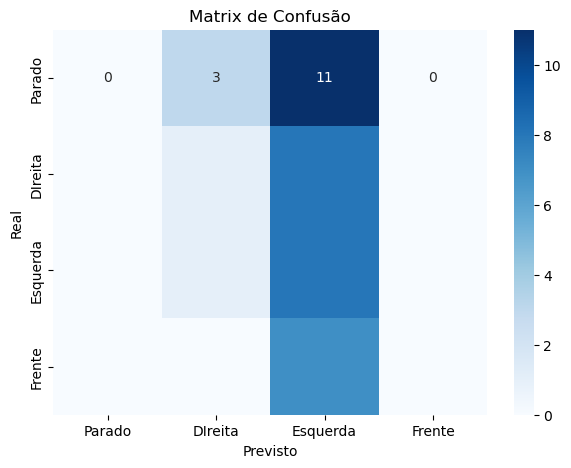

In [91]:
# Precisa do predictions = model.predict(X_test) realizado a cima

# Converte as probabilidades em rótulos de classe
predicted_classes = np.argmax(predictions, axis=1)
#true_classes = np.argmax(y_test, axis=1)
# Se y_test for unidimensional, use-o diretamente
true_classes = y_test if len(y_test.shape) == 1 else np.argmax(y_test, axis=1)

# Calcula a matriz de confusão
conf_matrix = confusion_matrix(true_classes, predicted_classes)
print(conf_matrix)

# Define os rótulos das classes
class_names = ['Parado', 'DIreita', 'Esquerda', 'Frente']

# Cria uma plotagem da matriz de confusão
plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matrix de Confusão')
plt.savefig('confusion_matrix_1Dcnn.png')
plt.show()